<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Documenta y verifica el paso de la capa **Silver → Gold** construyendo la **Constelación de Hechos (Galaxy Schema)**
lista para Power BI y validando el **cuadre contable exacto al céntimo** entre Bronze, Silver y Gold:

- **7 Dimensiones:** `dim_tiempo`, `dim_entidad_municipalidad`, `dim_geografia_ubigeo`, `dim_clasificador_ingreso`,
  `dim_fuente_rubro`, `dim_tipo_recurso` y `dim_formulario_pregunta`.
- **3 Tablas de Hechos:** `fact_ejecucion_ingresos`, `fact_metas_estadistica_atm` y `fact_cuestionario_atm`.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DecimalType
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [2]:
# Inicializar SparkSession
spark = (
    SparkSession.builder
    .appName("MEF_Galaxy_Gold_Cuadre")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.sql.shuffle.partitions", "50")
    .config("spark.memory.fraction", "0.8")
    .getOrCreate()
)

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark.sparkContext.setLogLevel("WARN")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas y lectura del modelo Gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Carga en memoria lógica (lectura lazy Parquet) las capas `bronze`, `silver` y las 10 tablas del modelo Gold.

In [3]:
%%time
BRONZE = "/home/jovyan/Final/proyecto_final/bronze"
SILVER = "/home/jovyan/Final/proyecto_final/silver"
GOLD   = "/home/jovyan/Final/proyecto_final/gold"

dim_tiempo       = spark.read.parquet(f"{GOLD}/dim_tiempo")
dim_entidad      = spark.read.parquet(f"{GOLD}/dim_entidad_municipalidad")
dim_geografia    = spark.read.parquet(f"{GOLD}/dim_geografia_ubigeo")
dim_clasificador = spark.read.parquet(f"{GOLD}/dim_clasificador_ingreso")
dim_rubro        = spark.read.parquet(f"{GOLD}/dim_fuente_rubro")
dim_tipo_rec     = spark.read.parquet(f"{GOLD}/dim_tipo_recurso")
dim_pregunta     = spark.read.parquet(f"{GOLD}/dim_formulario_pregunta")

fact_ingresos    = spark.read.parquet(f"{GOLD}/fact_ejecucion_ingresos")
fact_metas_atm   = spark.read.parquet(f"{GOLD}/fact_metas_estadistica_atm")
fact_cuest_atm   = spark.read.parquet(f"{GOLD}/fact_cuestionario_atm")

print("Tablas Gold cargadas correctamente.")

Tablas Gold cargadas correctamente.
CPU times: user 11.6 ms, sys: 20.1 ms, total: 31.7 ms
Wall time: 8.28 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Inventario dimensional y tablas de hechos en Gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Inspección de conteos y esquemas del Galaxy Schema estrictamente municipal (`NIVEL_GOBIERNO = 'M'`): 7 dimensiones (incluyendo `dim_tiempo` con soporte de `Mes_Numero = 13`
y `dim_entidad_municipalidad` con 1,964 municipalidades e imputación de mediana departamental para los 20 distritos creados post-2022) y 3 tablas de hechos.

In [4]:
tablas_gold = [
    ("dim_tiempo", dim_tiempo),
    ("dim_entidad_municipalidad", dim_entidad),
    ("dim_geografia_ubigeo", dim_geografia),
    ("dim_clasificador_ingreso", dim_clasificador),
    ("dim_fuente_rubro", dim_rubro),
    ("dim_tipo_recurso", dim_tipo_rec),
    ("dim_formulario_pregunta", dim_pregunta),
    ("fact_ejecucion_ingresos", fact_ingresos),
    ("fact_metas_estadistica_atm", fact_metas_atm),
    ("fact_cuestionario_atm", fact_cuest_atm),
]
for nombre, df_t in tablas_gold:
    print(f"{nombre:<28} | filas={df_t.count():>12,} | cols={len(df_t.columns):>2}")

print("\n--- Cobertura censal en dim_entidad_municipalidad ---")
dim_entidad.groupBy("Estado_Censal").count().orderBy(F.col("count").desc()).show(truncate=False)

print("--- Distritos post-2022 con imputación de mediana (muestra) ---")
dim_entidad.filter(F.col("Estado_Censal") == "Distrito Nuevo Post-Censo 2022").select(
    "SEC_EJEC", "UBIGEO", "Nombre_Municipalidad", "Tipomuni", "P32_1_T_Personal_Trib", "Personal_Total"
).show(5, truncate=False)

print("--- Esquema fact_ejecucion_ingresos ---")
fact_ingresos.printSchema()

dim_tiempo                   | filas=       6,592 | cols= 9
dim_entidad_municipalidad    | filas=       1,964 | cols=39
dim_geografia_ubigeo         | filas=       1,895 | cols= 8
dim_clasificador_ingreso     | filas=         432 | cols=13
dim_fuente_rubro             | filas=           6 | cols= 5
dim_tipo_recurso             | filas=         145 | cols= 5
dim_formulario_pregunta      | filas=         836 | cols=19
fact_ejecucion_ingresos      | filas=  10,401,713 | cols=17
fact_metas_estadistica_atm   | filas=      49,234 | cols=21
fact_cuestionario_atm        | filas=     322,675 | cols=17

--- Cobertura censal en dim_entidad_municipalidad ---
+------------------------------+-----+
|Estado_Censal                 |count|
+------------------------------+-----+
|Censado RENAMU 2022           |1944 |
|Distrito Nuevo Post-Censo 2022|20   |
+------------------------------+-----+

--- Distritos post-2022 con imputación de mediana (muestra) ---
+--------+------+-----------------------------

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Validacion del cuadre contable exacto al centimo (Bronze vs. Silver vs. Gold)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Compara los totales monetarios (`DecimalType(22, 2)`) a lo largo de las 3 capas del dominio SIAF (alcance estrictamente Municipal `'M'`).
En Silver se filtran `NIVEL_GOBIERNO = 'M'` y snapshots redundantes (`-23.83%` vs. bruto); en Gold (`fact_ejecucion_ingresos`) se descartan las **2,334,146 filas en cero** (`ES_FILA_SIN_MONTO`) y se agrupan con `SUM()`
los grupos duplicados de grano (`14` filas), manteniendo un cuadre de **S/ 0.00 de diferencia** respecto a Bronze neto municipal y Silver.

In [5]:
%%time
bronze_siaf = spark.read.parquet(f"{BRONZE}/siaf")
bronze_neto_m = (
    bronze_siaf
    .filter(~F.col("_archivo_origen").rlike(r"2025-Ingreso-Mensual\.csv|2026-Ingreso-Mensual\.csv"))
    .filter(F.trim(F.col("NIVEL_GOBIERNO")) == "M")
)
silver_siaf = spark.read.parquet(f"{SILVER}/siaf")

def resumen_siaf(df, desde_texto=False):
    pia = F.trim(F.col("MONTO_PIA")).cast(DecimalType(18, 2)) if desde_texto else F.col("MONTO_PIA")
    pim = F.trim(F.col("MONTO_PIM")).cast(DecimalType(18, 2)) if desde_texto else F.col("MONTO_PIM")
    rec = F.trim(F.col("MONTO_RECAUDADO")).cast(DecimalType(18, 2)) if desde_texto else F.col("MONTO_RECAUDADO")
    r = df.agg(
        F.count("*").alias("filas"),
        F.sum(pia).cast(DecimalType(22, 2)).alias("pia"),
        F.sum(pim).cast(DecimalType(22, 2)).alias("pim"),
        F.sum(rec).cast(DecimalType(22, 2)).alias("rec"),
    ).collect()[0]
    return r["filas"], r["pia"], r["pim"], r["rec"]

etapas = [
    ("Bronze Bruto (20 CSV)",     resumen_siaf(bronze_siaf, True)),
    ("Bronze Neto Muni ('M')",    resumen_siaf(bronze_neto_m, True)),
    ("Silver Muni (siaf)",        resumen_siaf(silver_siaf, False)),
    ("Gold Muni (fact_ejecuc.)",  resumen_siaf(fact_ingresos, False)),
]
print(f"{'Capa':<24} | {'Filas':>12} | {'PIA (S/)':>22} | {'PIM (S/)':>22} | {'Recaudado (S/)':>22}")
print("-" * 112)
for nombre, (filas, pia, pim, rec) in etapas:
    print(f"{nombre:<24} | {filas:>12,} | {pia:>22,.2f} | {pim:>22,.2f} | {rec:>22,.2f}")

# Verificar diferencia exactamente 0.00 entre Bronze Neto Municipal, Silver y Gold
_, pia_bn, pim_bn, rec_bn = etapas[1][1]
_, pia_g,  pim_g,  rec_g  = etapas[3][1]
assert pia_bn == pia_g and pim_bn == pim_g and rec_bn == rec_g
print(f"\nVALIDACION AL CENTIMO ('M') -> Dif PIA: {pia_g - pia_bn:.2f} | Dif PIM: {pim_g - pim_bn:.2f} | Dif Recaudado: {rec_g - rec_bn:.2f}")

Capa                     |        Filas |               PIA (S/) |               PIM (S/) |         Recaudado (S/)
----------------------------------------------------------------------------------------------------------------
Bronze Bruto (20 CSV)    |   16,719,553 |   1,165,690,206,489.00 |   1,661,810,691,699.00 |   1,825,254,431,926.16
Bronze Neto Muni ('M')   |   12,735,873 |     327,811,008,619.00 |     590,726,087,898.00 |     579,058,362,731.05
Silver Muni (siaf)       |   12,735,873 |     327,811,008,619.00 |     590,726,087,898.00 |     579,058,362,731.05
Gold Muni (fact_ejecuc.) |   10,401,713 |     327,811,008,619.00 |     590,726,087,898.00 |     579,058,362,731.05

VALIDACION AL CENTIMO ('M') -> Dif PIA: 0.00 | Dif PIM: 0.00 | Dif Recaudado: 0.00
CPU times: user 74.6 ms, sys: 27.2 ms, total: 102 ms
Wall time: 18.5 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Auditoria de asientos contables negativos (ES_EXTORNO_NEGATIVO)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Demuestra que los registros con `MONTO_RECAUDADO < 0` (extornos, anulaciones y devoluciones tributarias)
se conservan íntegramente bajo el flag `ES_EXTORNO_NEGATIVO` para garantizar el principio de percibido neto.

In [6]:
neg_silver_loc = silver_siaf.filter(F.col("ES_EXTORNO_NEGATIVO")).agg(
    F.count("*").alias("n"),
    F.sum("MONTO_RECAUDADO").cast(DecimalType(22, 2)).alias("suma"),
    F.min("MONTO_RECAUDADO").cast(DecimalType(22, 2)).alias("minimo"),
).collect()[0]
neg_gold = fact_ingresos.filter(F.col("ES_EXTORNO_NEGATIVO")).agg(
    F.count("*").alias("n"),
    F.sum("MONTO_RECAUDADO").cast(DecimalType(22, 2)).alias("suma"),
).collect()[0]

print(f"Silver Recaudado < 0 (Municipal 'M')   : {neg_silver_loc['n']:>8,} filas | Suma: S/ {neg_silver_loc['suma']:>18,.2f} | Min: S/ {neg_silver_loc['minimo']:,.2f}")
print(f"Gold   Recaudado < 0 (Agrupado grano)  : {neg_gold['n']:>8,} filas | Suma: S/ {neg_gold['suma']:>18,.2f}")
assert neg_silver_loc['suma'] == neg_gold['suma']

Silver Recaudado < 0 (Municipal 'M')   :   72,194 filas | Suma: S/  -8,099,958,601.69 | Min: S/ -88,369,790.06
Gold   Recaudado < 0 (Agrupado grano)  :   72,192 filas | Suma: S/  -8,099,958,601.69


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Integridad referencial (0 huerfanos) y visualizacion resumen Gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Verifica con `left_anti` joins que el 100% de las claves foráneas en las 3 tablas de hechos enlazan con sus dimensiones
(**0 registros huérfanos**) y grafica la ejecución municipal por Tipo de Municipalidad (`Provincial` vs. `Distrital`) desde Gold.

In [7]:
checks = [
    ("fact_ejecucion_ingresos.SK_Fecha",       fact_ingresos.join(dim_tiempo, "SK_Fecha", "left_anti").count()),
    ("fact_ejecucion_ingresos.SK_Muni",        fact_ingresos.join(dim_entidad, "SK_Municipalidad", "left_anti").count()),
    ("fact_ejecucion_ingresos.SK_Ubigeo",      fact_ingresos.join(dim_geografia, "SK_Ubigeo", "left_anti").count()),
    ("fact_ejecucion_ingresos.SK_Clasif",      fact_ingresos.join(dim_clasificador, "SK_Clasificador", "left_anti").count()),
    ("fact_ejecucion_ingresos.SK_Rubro",       fact_ingresos.join(dim_rubro, "SK_Fuente_Rubro", "left_anti").count()),
    ("fact_ejecucion_ingresos.SK_TipoRec",     fact_ingresos.join(dim_tipo_rec, "SK_Tipo_Recurso", "left_anti").count()),
    ("fact_metas_estadistica_atm.SK_Fecha",   fact_metas_atm.join(dim_tiempo, "SK_Fecha", "left_anti").count()),
    ("fact_metas_estadistica_atm.SK_Muni",    fact_metas_atm.join(dim_entidad, "SK_Municipalidad", "left_anti").count()),
    ("fact_metas_estadistica_atm.SK_Ubigeo",  fact_metas_atm.join(dim_geografia, "SK_Ubigeo", "left_anti").count()),
    ("fact_cuestionario_atm.SK_Fecha",        fact_cuest_atm.join(dim_tiempo, "SK_Fecha", "left_anti").count()),
    ("fact_cuestionario_atm.SK_Muni",         fact_cuest_atm.join(dim_entidad, "SK_Municipalidad", "left_anti").count()),
    ("fact_cuestionario_atm.SK_Ubigeo",       fact_cuest_atm.join(dim_geografia, "SK_Ubigeo", "left_anti").count()),
    ("fact_cuestionario_atm.SK_Pregunta",     fact_cuest_atm.join(dim_pregunta, "SK_Pregunta", "left_anti").count()),
]
for rel, huerfanos in checks:
    assert huerfanos == 0, f"Huérfanos detectados en {rel}: {huerfanos}"
    print(f"OK (0 huérfanos) -> {rel}")

OK (0 huérfanos) -> fact_ejecucion_ingresos.SK_Fecha
OK (0 huérfanos) -> fact_ejecucion_ingresos.SK_Muni
OK (0 huérfanos) -> fact_ejecucion_ingresos.SK_Ubigeo
OK (0 huérfanos) -> fact_ejecucion_ingresos.SK_Clasif
OK (0 huérfanos) -> fact_ejecucion_ingresos.SK_Rubro
OK (0 huérfanos) -> fact_ejecucion_ingresos.SK_TipoRec
OK (0 huérfanos) -> fact_metas_estadistica_atm.SK_Fecha
OK (0 huérfanos) -> fact_metas_estadistica_atm.SK_Muni
OK (0 huérfanos) -> fact_metas_estadistica_atm.SK_Ubigeo
OK (0 huérfanos) -> fact_cuestionario_atm.SK_Fecha
OK (0 huérfanos) -> fact_cuestionario_atm.SK_Muni
OK (0 huérfanos) -> fact_cuestionario_atm.SK_Ubigeo
OK (0 huérfanos) -> fact_cuestionario_atm.SK_Pregunta


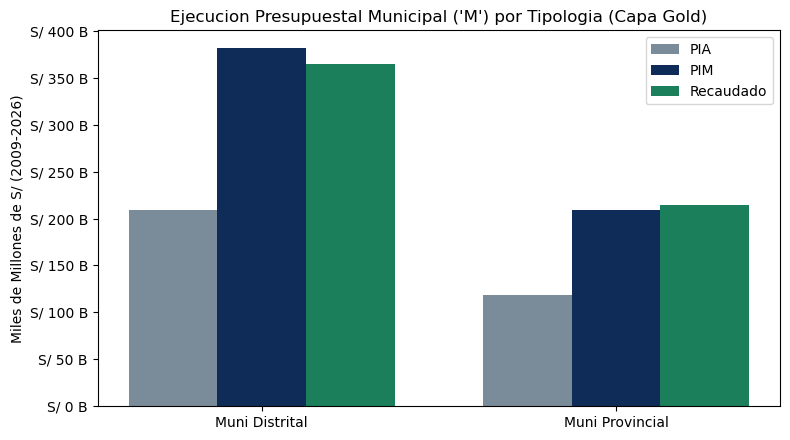

In [8]:
# Agregacion municipal por Tipo_Municipalidad en Gold para graficar en el driver (solo 2 filas)
res_nivel_pd = (
    fact_ingresos
    .join(F.broadcast(dim_entidad.select("SK_Municipalidad", "Tipo_Municipalidad")), "SK_Municipalidad")
    .groupBy("Tipo_Municipalidad")
    .agg(
        (F.sum("MONTO_PIA") / 1e9).cast("double").alias("PIA_MM"),
        (F.sum("MONTO_PIM") / 1e9).cast("double").alias("PIM_MM"),
        (F.sum("MONTO_RECAUDADO") / 1e9).cast("double").alias("REC_MM"),
    )
    .orderBy(F.col("REC_MM").desc())
    .toPandas()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(res_nivel_pd))
w = 0.25
ax.bar([i - w for i in x], res_nivel_pd["PIA_MM"], width=w, label="PIA", color="#7A8B99")
ax.bar(x, res_nivel_pd["PIM_MM"], width=w, label="PIM", color="#0F2C59")
ax.bar([i + w for i in x], res_nivel_pd["REC_MM"], width=w, label="Recaudado", color="#1B7F5B")
ax.set_xticks(list(x))
ax.set_xticklabels([f"Muni {t}" for t in res_nivel_pd["Tipo_Municipalidad"]])
ax.set_ylabel("Miles de Millones de S/ (2009-2026)")
ax.set_title("Ejecucion Presupuestal Municipal ('M') por Tipologia (Capa Gold)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("S/ {x:,.0f} B"))
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
spark.stop()